# 03 - The model: logistic regression with honest probabilities

**The big picture**
1. Sections 1-5 use the **training** data only. We pick the model setting `C`, check the probabilities are honest,
   and choose the cut-off for "who gets a retention offer".
2. Section 6 **saves** the finished model and settings to disk.
3. Section 7 opens the **test** data for the first and only time and grades the saved model against simple baselines.

Nothing is changed after seeing test results. Each step below says **what** it does, **why**, and **what to say if asked**.

## 1. Setup and load the training data
**What:** loads `train.csv` and the model recipe from `src/modeling.py`.
**Why:** `modeling.py` holds the whole pipeline (relabel, fill gaps, scale numbers, one-hot encode, logistic regression)
in one object, so the Streamlit app can later feed in raw customer details and get the same treatment as the training data.
**If asked:** *"Every preprocessing step lives inside one scikit-learn Pipeline, so nothing is learned from the test data
and there is no mismatch between training and the app."*

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # the project folder
sys.path.insert(0, str(ROOT / "src"))
from modeling import AUDIT_COLS, FEATURES, build_pipeline, split_xy

TRAIN_CSV = ROOT / "data" / "processed" / "train.csv"
TEST_CSV = ROOT / "data" / "processed" / "test.csv"
MODEL_PATH = ROOT / "models" / "churn_pipeline.joblib"
CONFIG_PATH = ROOT / "models" / "model_config.json"
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"      # chart colours (colour-blind-safe pair)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.axisbelow": True, "font.size": 9,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})

train = pd.read_csv(TRAIN_CSV)
X_train, y_train = split_xy(train)                       # the 16 input columns, and the 0/1 churn answer
assert not set(AUDIT_COLS) & set(X_train.columns)        # gender and SeniorCitizen are NOT inputs
assert "TotalCharges" not in X_train.columns
print(f"{len(X_train):,} training customers, {len(FEATURES)} input columns, churn rate {y_train.mean():.1%}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # 5 train/validate rounds inside the training data

4,930 training customers, 16 input columns, churn rate 26.5%


## 2. Choose `C` (how strongly to hold the model back)
**What:** `C` is a dial. A small `C` keeps the model's weights small (a simpler model); a large `C` lets them grow.
We try six values and keep the one with the lowest *log-loss* (an error score that punishes confident wrong answers) on
held-back slices of the training data (5-fold cross-validation).
**Why:** log-loss rewards honest probabilities, which we need for the revenue-at-risk number.
**If asked:** *"With about 23 inputs the model barely overfits, so many values of C work equally well; I picked the
best of six."*

In [2]:
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    result = cross_validate(build_pipeline(C), X_train, y_train, cv=cv, scoring="neg_log_loss")
    rows.append({"C": C, "log-loss (lower is better)": -result["test_score"].mean()})
c_table = pd.DataFrame(rows)
best_C = float(c_table.loc[c_table["log-loss (lower is better)"].idxmin(), "C"])
display(c_table.round(4).style.hide(axis="index"))
print(f"Chosen C = {best_C}")

C,log-loss (lower is better)
0.001000,0.478200
0.010000,0.425000
0.100000,0.419200
1.000000,0.419400
10.000000,0.419600
100.000000,0.419800


Chosen C = 0.1


## 3. Are the probabilities honest? (calibration)
**What:** every training customer gets a churn probability from a model that never saw them (5-fold, "out-of-fold").
Then we ask: of the customers given about 30%, did about 30% really churn? The chart plots predicted vs actual. On the
dashed diagonal = honest.
**Why:** the revenue-at-risk number multiplies probability by money. If the probabilities are inflated, so is the number.
**Contrast:** the popular `class_weight="balanced"` setting makes the model pay extra attention to churners. It changes the
average predicted churn rate from the true 26.5% to about 42%, so it would inflate any dollar figure.

Pre-set pass rule (decided before looking): calibration slope between 0.85 and 1.15, and intercept within +/-0.10
(slope 1 and intercept 0 are perfect).
**If asked:** *"I checked that when the model says 30%, about 30% churn, and showed that class weights break this."*

,average predicted risk,actual churn rate,slope,intercept,Brier score
model,,,,,
plain (used),0.265,0.265,1.018,0.010,0.136
"class_weight=""balanced""",0.416,0.265,1.018,-1.018,0.166


Brier score if we always guessed 26.5%: 0.195   (lower is better; the plain model beats it)
Pre-set rule: PASS - keep the plain model


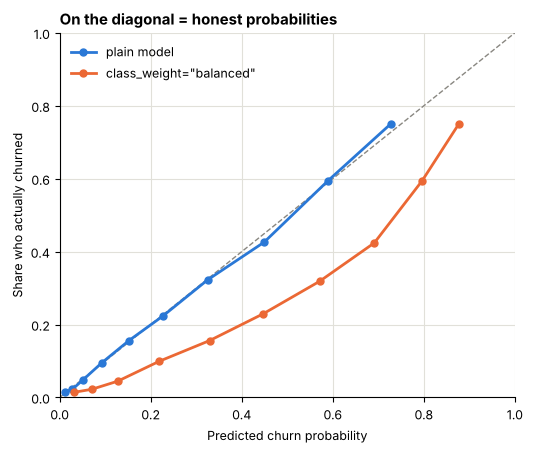

In [3]:
oof_plain = cross_val_predict(build_pipeline(best_C), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof_balanced = cross_val_predict(build_pipeline(best_C, class_weight="balanced"), X_train, y_train,
                                 cv=cv, method="predict_proba")[:, 1]

def calibration_stats(y, p):
    # Fit  actual outcome ~ a + b * logit(p).  Perfect honesty: b (slope) = 1 and a (intercept) = 0.
    p = np.clip(p, 1e-6, 1 - 1e-6)
    fit = LogisticRegression(C=1e6, max_iter=1000).fit(np.log(p / (1 - p)).reshape(-1, 1), y)
    return float(fit.coef_[0, 0]), float(fit.intercept_[0])

base_brier = y_train.mean() * (1 - y_train.mean())        # the Brier score of always guessing "26.5%"
rows = []
for name, p in (("plain (used)", oof_plain), ('class_weight="balanced"', oof_balanced)):
    slope, intercept = calibration_stats(y_train, p)
    rows.append({"model": name, "average predicted risk": p.mean(), "actual churn rate": y_train.mean(),
                 "slope": slope, "intercept": intercept, "Brier score": brier_score_loss(y_train, p)})
display(pd.DataFrame(rows).set_index("model").round(3))
print(f"Brier score if we always guessed {y_train.mean():.1%}: {base_brier:.3f}   (lower is better; the plain model beats it)")

slope, intercept = calibration_stats(y_train, oof_plain)
calibration_ok = (0.85 <= slope <= 1.15) and (abs(intercept) <= 0.10)
print("Pre-set rule:", "PASS - keep the plain model" if calibration_ok else "FAIL - would need a calibration wrapper")

fig, ax = plt.subplots(figsize=(5.4, 4.6))
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1)
for p, colour, label in ((oof_plain, BLUE, "plain model"), (oof_balanced, ORANGE, 'class_weight="balanced"')):
    actual, predicted = calibration_curve(y_train, p, n_bins=10, strategy="quantile")
    ax.plot(predicted, actual, color=colour, marker="o", markersize=5, linewidth=2, label=label)
ax.set_xlabel("Predicted churn probability")
ax.set_ylabel("Share who actually churned")
ax.set_title("On the diagonal = honest probabilities")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "model_01_calibration.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Choose the cut-off: who gets a retention offer?
**What:** a simple money rule. Suppose an offer is a discount `d` on the bill, and an offer saves a would-be churner with
probability `s`. For a customer with churn probability `p`:
- gain if they would have left and we save them: roughly `p x s x (1 - d)` of their bill
- cost if they would have stayed: the discount `(1 - p) x d`

The offer is worth making when the gain beats the cost, which gives `p > d / (s x (1 - d) + d)`. The number of months
cancels out, so it is not needed.

**These inputs are assumptions, not data:** a 10% discount (`d = 0.10`) and 30% of would-be leavers saved (`s = 0.30`).
The table shows how the cut-off moves if the assumptions change.
**Why it needs honest probabilities:** the rule compares `p` directly with the cut-off.
**If asked:** *"The threshold comes from a stated cost trade-off, not from chasing recall. The inputs are assumptions I can
change; the method is the point."*

In [4]:
D, S = 0.10, 0.30                                    # ASSUMPTIONS: 10% discount, 30% of would-be churners saved

def cutoff(d, s):
    return d / (s * (1 - d) + d)

THRESHOLD = round(cutoff(D, S), 2)                   # 0.27: offer when the churn probability is 27% or more
print(f"Offer when the churn probability is at least {THRESHOLD:.0%}")

display(pd.DataFrame({f"saves {int(s * 100)}%": [cutoff(d, s) for d in (0.05, 0.10, 0.20)] for s in (0.15, 0.30, 0.50)},
                     index=[f"{int(d * 100)}% discount" for d in (0.05, 0.10, 0.20)]).round(2))

flag = oof_plain >= THRESHOLD
caught = int((flag & (y_train == 1)).sum())
print(f"On training data (out-of-fold) this flags {flag.mean():.0%} of customers, "
      f"catches {caught / y_train.sum():.0%} of the churners, and {caught / flag.sum():.0%} of flagged customers really churn.")

Offer when the churn probability is at least 27%


,saves 15%,saves 30%,saves 50%
5% discount,0.26,0.15,0.10
10% discount,0.43,0.27,0.18
20% discount,0.62,0.45,0.33


On training data (out-of-fold) this flags 40% of customers, catches 79% of the churners, and 52% of flagged customers really churn.


## 5. What did the model learn? (sanity check)
**What:** the model's weights (coefficients) after fitting. Numbers were standardised, so a numeric weight means "per one
standard deviation". Positive = pushes toward churn.
**Why:** the EDA said contract, tenure, internet type, security and support matter most. The signs below should agree.
**If asked:** *"Month-to-month and fibre push risk up; long tenure, two-year contracts and having security or support push
it down, which matches the data."*

In [5]:
final_model = build_pipeline(best_C).fit(X_train, y_train)
names = final_model[:-1].get_feature_names_out()
weights = pd.Series(final_model[-1].coef_[0], index=names).sort_values()
display(pd.concat([weights.head(6), weights.tail(6)]).round(2).to_frame("weight"))

,weight
tenure,-0.76
InternetService_No,-0.59
Contract_Two year,-0.57
PhoneService_Yes,-0.47
OnlineSecurity_Yes,-0.42
TechSupport_Yes,-0.38
MultipleLines_Yes,0.25
PaymentMethod_Electronic check,0.27
MonthlyCharges,0.35
PaperlessBilling_Yes,0.40


## 6. Save the model (before any test data is opened)
**What:** writes the fitted pipeline and the settings we chose to `models/`.
**Why:** the test evaluation below loads these files, so it cannot be influenced by anything done afterwards.

In [6]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, MODEL_PATH)

config = {
    "model": "LogisticRegression (L2) inside an sklearn Pipeline",
    "C": best_C,
    "threshold": THRESHOLD,
    "cost_assumptions": {"discount": D, "save_rate": S},
    "calibration_on_training_out_of_fold": {"slope": slope, "intercept": intercept, "passed_preset_rule": bool(calibration_ok)},
    "input_columns": FEATURES,
    "audit_only_columns_not_given_to_model": AUDIT_COLS,
    "sklearn_version": sklearn.__version__,
}
CONFIG_PATH.write_text(json.dumps(config, indent=2))
print("Saved", MODEL_PATH.relative_to(ROOT), "and", CONFIG_PATH.relative_to(ROOT))

Saved models/churn_pipeline.joblib and models/model_config.json


## 7. Grade the saved model on the test set (first and only time)
**What:** loads the saved model, scores the 2,113 test customers, and compares it with simple baselines:
- **Always predict "no churn"** (about 73% right, but catches nobody).
- **Offer to everyone.**
- **A one-line rule:** flag every month-to-month customer.
- **The model at our cut-off**, and **the model flagging the same number of customers as the rule** (a fair head-to-head).

Terms: **recall** = of the customers who really churned, the share we flagged. **Precision** = of the customers we flagged,
the share who really churned.
**If asked:** *"A model only counts if it beats a simple rule on customers it never saw."*

In [7]:
config = json.loads(CONFIG_PATH.read_text())
model = joblib.load(MODEL_PATH)
threshold = config["threshold"]

test = pd.read_csv(TEST_CSV)
X_test, y_test = split_xy(test)
p_test = model.predict_proba(X_test)[:, 1]
print(f"{len(X_test):,} test customers, churn rate {y_test.mean():.1%}")

def summarise(flagged):
    tp = int((flagged & (y_test == 1)).sum())
    return {"customers flagged": flagged.mean(),
            "recall": tp / y_test.sum(),
            "precision": tp / flagged.sum() if flagged.sum() else np.nan,
            "accuracy": (flagged == (y_test == 1)).mean()}

rule = (X_test["Contract"] == "Month-to-month").to_numpy()
same_rate = np.zeros(len(p_test), dtype=bool)
same_rate[np.argsort(-p_test)[:int(rule.sum())]] = True          # the model's top-ranked customers, as many as the rule flags

table = pd.DataFrame({
    "Always predict no churn": summarise(np.zeros(len(y_test), dtype=bool)),
    "Offer to everyone": summarise(np.ones(len(y_test), dtype=bool)),
    "Rule: month-to-month contract": summarise(rule),
    f"Model at cut-off {threshold:.2f}": summarise(p_test >= threshold),
    "Model, same number flagged as the rule": summarise(same_rate),
}).T
table.style.format("{:.1%}")

2,113 test customers, churn rate 26.5%


,customers flagged,recall,precision,accuracy
Always predict no churn,0.0%,0.0%,nan%,73.5%
Offer to everyone,100.0%,100.0%,26.5%,26.5%
Rule: month-to-month contract,55.4%,88.4%,42.4%,65.0%
Model at cut-off 0.27,40.5%,78.1%,51.2%,74.4%
"Model, same number flagged as the rule",55.4%,92.3%,44.2%,67.1%


ROC-AUC:  0.842   (0.5 = coin flip, 1.0 = perfect ranking of churners above loyal customers)
Brier:    0.137   (always guessing 26.5% would score 0.195; lower is better)
Calibration on unseen customers: slope 1.02, intercept 0.00  (perfect = 1 and 0)


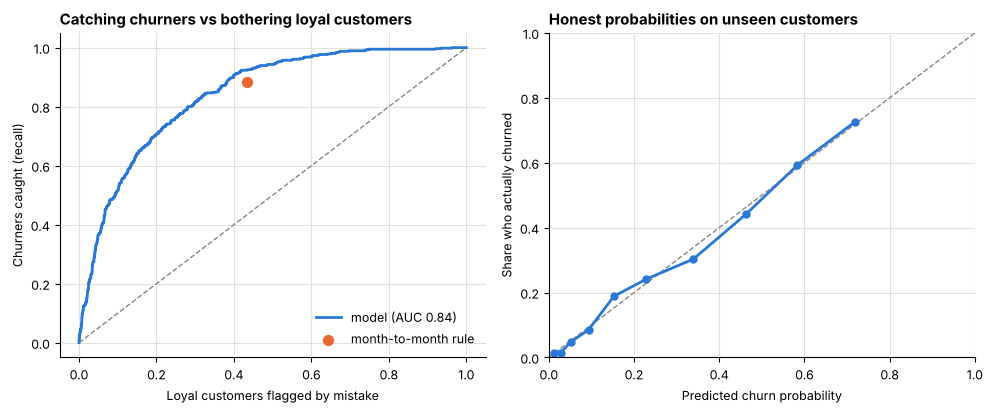

In [8]:
slope_t, intercept_t = calibration_stats(y_test, p_test)
print(f"ROC-AUC:  {roc_auc_score(y_test, p_test):.3f}   (0.5 = coin flip, 1.0 = perfect ranking of churners above loyal customers)")
print(f"Brier:    {brier_score_loss(y_test, p_test):.3f}   (always guessing {y_test.mean():.1%} would score {y_test.mean() * (1 - y_test.mean()):.3f}; lower is better)")
print(f"Calibration on unseen customers: slope {slope_t:.2f}, intercept {intercept_t:.2f}  (perfect = 1 and 0)")

fpr, tpr, _ = roc_curve(y_test, p_test)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

ax = axes[0]
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1)
ax.plot(fpr, tpr, color=BLUE, linewidth=2, label=f"model (AUC {roc_auc_score(y_test, p_test):.2f})")
ax.scatter([(rule & (y_test == 0)).sum() / (y_test == 0).sum()], [(rule & (y_test == 1)).sum() / y_test.sum()],
           color=ORANGE, s=50, zorder=5, label="month-to-month rule")
ax.set_xlabel("Loyal customers flagged by mistake")
ax.set_ylabel("Churners caught (recall)")
ax.set_title("Catching churners vs bothering loyal customers")
ax.legend(loc="lower right", frameon=False)

ax = axes[1]
actual, predicted = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1)
ax.plot(predicted, actual, color=BLUE, marker="o", markersize=5, linewidth=2)
ax.set_xlabel("Predicted churn probability")
ax.set_ylabel("Share who actually churned")
ax.set_title("Honest probabilities on unseen customers")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

fig.tight_layout()
fig.savefig(FIGS / "model_02_test_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. What this tells us, and what it does not

**What the evidence supports**
1. **The model ranks customers well and its probabilities are honest.** On the 2,113 unseen customers the ROC-AUC is
   0.842 (a coin flip is 0.5; the one-line contract rule scores 0.725). The calibration slope is
   1.02 and the intercept 0.00 (perfect = 1 and 0), and the Brier score is 0.137
   against 0.195 for always guessing 26.5%.
2. **Class weights would have broken the probabilities.** With `class_weight="balanced"` the average predicted churn rate
   was about 42% instead of the true 26.5% (section 3).
3. **A one-line rule is a strong baseline.** "Flag every month-to-month customer" flags 55% of customers and
   catches 88.4% of churners (precision 42.4%). At the **same number flagged**, the model
   catches 92.3% (precision 44.2%): better, but the margin is modest.
4. **At our cut-off the model is more selective.** It flags 40% of customers (about 15 points fewer than
   the rule), catches 78.1% of churners, and 51.2% of the people it flags really churn.
5. **Accuracy is the wrong yardstick.** The model's accuracy (74.4%) is barely above "always predict no churn"
   (73.5%). The real question is who to prioritise, not how often a label is guessed right.
6. **The weights agree with the EDA** (section 5): month-to-month contracts, fibre internet, paperless billing and higher
   bills push risk up; long tenure, two-year contracts, online security and tech support push it down.

**Limits to state honestly**
- **The offer economics are assumptions** (10% discount, 30% saved). The cut-off moves between about 0.10 and 0.62 across
  plausible values (section 4). The method is the point, not the exact number.
- **One test set.** It has 561 churners, so differences of a point or two are noise. I did not run a formal
  significance test, so "the model beats the rule" is suggestive, not proven.
- **Read weights together, not one by one.** For example `PhoneService_Yes` has a negative weight even though its raw link
  to churn is near zero, because it overlaps with `InternetService` and `MultipleLines`.
- **No time horizon.** `Churn = Yes` means the customer had already left, so scores describe "customers who resemble past
  churners", not a forecast for next quarter.
- **Fairness is not tested here.** Leaving out `gender` and `SeniorCitizen` is a design choice; notebook 04 measures what
  actually happens to those groups.